# 03. 하이브리드 필터링 (CF + CBF 순위 결합)
**머신러닝 팀프로젝트 2조 | 음악 아티스트 추천 (Last.fm)**  |  모델 평가 및 결과 통합

---
## 목적
이 노트북은 **협업 필터링(CF)** 과 **콘텐츠 기반 필터링(CBF)** 의 추천 순위를 결합한 **하이브리드 필터링**을 구현합니다. 두 모델은 서로 다른 정보를 사용합니다.
- **CF**: 사용자들의 청취 기록(누가 무엇을 들었는가)에서 비슷한 사용자를 찾아 추천합니다. 정확도가 높지만 이미 인기 있는 아티스트에 추천이 몰리는 경향이 있습니다.
- **CBF**: 아티스트에 붙은 태그(장르·분위기)의 유사도로 추천합니다. 덜 알려진 아티스트까지 추천해 다양성이 높지만 정확도는 낮습니다.

두 방식은 장단점이 상반되므로, 순위를 결합하면 CF의 정확도를 유지하면서 CBF의 다양성을 일부 얻을 수 있는지 확인하는 것이 목적입니다. 모델 간 성능 비교와 통계 분석은 **04 통합 평가 노트북**에서 수행하며, 이 노트북의 출력이 04의 입력이 됩니다.

## 전체 처리 흐름
```
[0] 설정·상수 정의
 → [1] 전처리 데이터 로드 및 분할 누수 검사
 → [2] CF·CBF 모델 함수 정의 (기존 노트북 코드를 수정 없이 사용)
 → [3] 하이브리드 결합 함수 fuse() 정의
 → [4] Dataset A: 공통 후보 정의 → Validation에서 가중치 w 탐색·확정 → Test 추천 생성
 → [5] Dataset B: (5-1) CF 노트북 조건의 공식 CF·인기순 추천 → (5-2) 확정한 w로 공통 후보 기준 4개 모델 추천 생성
 → [6] 설정·산출물 저장 (04 노트북의 입력)
```

## 설계 방침 (이렇게 구현한 이유)
1. **CF·CBF 코드를 수정하지 않고 재사용합니다.** 하이브리드의 입력(각 모델의 Top-50)이 기존 노트북의 추천 결과와 동일해야 하이브리드 효과를 순수하게 측정할 수 있습니다.
2. **네 모델이 같은 후보 집합에서 추천합니다.** CF는 관측된 모든 아티스트를, CBF는 태그가 있는 아티스트만 추천할 수 있어 후보가 다릅니다. 후보가 다르면 정확도와 다양성(Coverage)을 공정하게 비교할 수 없으므로 두 집합의 교집합(공통 후보)으로 맞춥니다.
3. **점수가 아니라 순위를 결합합니다.** CF 점수(이웃 유사도 가중 합)와 CBF 점수(코사인 유사도)는 값의 범위와 의미가 달라 직접 더할 수 없습니다.
4. **Dataset B의 기준 수치는 CF 노트북의 평가 조건을 따릅니다.** B에서 CF·인기순은 CF 노트북과 똑같은 조건(B 전체 이력, 전체 후보, 전체 정답)으로 먼저 추천·평가하여 공식 결과와 같은 수치를 재현합니다. 공통 후보 기준 결과는 CBF·하이브리드까지 포함한 상대 비교용 보조 기준입니다.
5. **가중치는 Dataset A의 Validation에서만 정합니다.** Test와 Dataset B는 최종 평가에만 사용하여 선택 과정에 평가 데이터가 개입하는 것(데이터 누수)을 막습니다.

## 평가 원칙
- 설정은 A-validation NDCG@10으로만 선택, A-test와 B는 최종 평가에만 사용, B로 설정을 바꾸지 않습니다.
- 하이브리드 가중치도 A-validation에서만 정하고 B에는 그대로 적용합니다.
- Test 기록은 유사도·프로필·인기도 계산에 쓰지 않습니다.

## 하이브리드 방식: 가중 RRF
CF 점수(이웃 유사도 합)와 CBF 점수(코사인 유사도)는 **척도가 달라 점수를 직접 더할 수 없습니다.** 그래서 점수가 아니라 **순위**를 결합하는 RRF를 씁니다.

$$\text{score}(u,i)=w\cdot\frac{1}{c+\text{rank}_{CF}(u,i)}+(1-w)\cdot\frac{1}{c+\text{rank}_{CBF}(u,i)}$$

- 한쪽 목록에만 있는 아티스트는 그쪽 항만 더합니다. 두 목록 모두에 있으면 두 항이 합쳐져 위로 올라갑니다.
- `c = 60`은 Cormack et al. (2009)의 권장 상수이며 고정합니다. 튜닝하는 값은 CF 가중치 `w` 하나(0~1, 0.1 간격)입니다.
- 두 모델이 결합할 후보는 각 모델의 **Top-50** 입니다.
- **공통 후보:** CF·CBF·인기순·하이브리드가 모두 같은 후보 집합(CBF 후보 ∩ 관측된 아티스트)에서 추천하도록 맞춰, Coverage 분모와 후보 집합 차이로 인한 왜곡을 없앱니다.

출처: Cormack, G. V., Clarke, C. L. A., & Büttcher, S. (2009). Reciprocal rank fusion outperforms Condorcet and individual rank learning methods. *SIGIR '09*.

## 0. 설정과 상수
하이브리드에서 쓰는 값을 한곳에 정의합니다.
- `TOPK = 10`: 최종 추천과 평가의 길이입니다.
- `POOL = 50`: 결합에 사용할 각 모델의 후보 목록 길이입니다. 최종 추천은 10개이지만 한쪽 모델에서 10위 밖(예: 11~50위)에 있던 아티스트가 다른 모델의 순위와 합쳐져 상위로 올라올 수 있도록 넉넉하게 잡았습니다.
- `RRF_C = 60`: RRF의 상수로, 원 논문(Cormack et al., 2009)의 권장값을 그대로 사용하며 튜닝하지 않습니다. 튜닝 대상을 가중치 `w` 하나로 제한하여 탐색 범위와 과적합 위험을 줄입니다.
- `W_GRID`: CF 가중치 `w`의 탐색 범위(0.0~1.0, 간격 0.1)입니다. 양 끝값은 각각 CBF 단독(0.0), CF 단독(1.0)과 같아 결합 효과를 비교하는 기준이 됩니다.
- 이 노트북은 CF·CBF 노트북에서 확정한 설정(`k=30`, log1p 가중치 / raw TF, uniform 프로필)을 그대로 사용합니다. 설정 파일이 있으면 읽고 없으면 같은 기본값을 사용합니다.

In [25]:
# 0. 설정
import os, io, json, zipfile, pathlib, hashlib, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.preprocessing import normalize
from IPython.display import display
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
TOPK = 10                 # 평가·최종 추천 개수
POOL = 50                 # 하이브리드가 결합할 각 모델의 후보 목록 길이
RRF_C = 60                # RRF 상수 (Cormack et al., 2009 권장값)
W_GRID = [round(x, 1) for x in np.arange(0, 1.01, 0.1)]     # CF 가중치 탐색 범위 (0 = CBF만, 1 = CF만)

# ---- 경로 설정 --------------------------------------------------------------------------
BASE_DIR = pathlib.Path.cwd()          # 작업 폴더(노트북이 있는 폴더). 다른 위치를 쓰려면 직접 지정: pathlib.Path('/path/to/ml_project')
ZIP_PATH = None                        # 전처리 ZIP 경로를 직접 지정하려면 입력 (None이면 BASE_DIR, BASE_DIR/data 에서 ZIP을 자동 탐색)
OUT = BASE_DIR / 'hybrid_outputs'; OUT.mkdir(parents=True, exist_ok=True)
# CF·CBF 노트북의 확정 설정 파일 (있으면 읽고, 없으면 기본값 사용)
CF_CONFIG_PATH = BASE_DIR / 'cf_outputs' / 'selected_config.json'
CBF_CONFIG_PATH = BASE_DIR / 'cbf_outputs' / 'selected_config.json'
CF_DEFAULT = {'k': 30, 'weight': 'log'}                       # CF 노트북 최종 결과 (A-validation NDCG@10 기준)
CBF_DEFAULT = {'tf_mode': 'raw', 'weight_mode': 'uniform'}    # CBF 노트북 최종 결과

def load_config(path, default, name):
    if path.exists():
        cfg = json.loads(path.read_text(encoding='utf-8')); print(f'{name} 설정을 {path} 에서 읽음:', {k: cfg[k] for k in default}); return {k: cfg[k] for k in default}
    print(f'{name} 설정 파일이 없어 기본값 사용:', default); return dict(default)
CF_CFG = load_config(CF_CONFIG_PATH, CF_DEFAULT, 'CF')
CBF_CFG = load_config(CBF_CONFIG_PATH, CBF_DEFAULT, 'CBF')
print('결과 저장 위치:', OUT)

CF 설정을 ./cf_outputs/selected_config.json 에서 읽음: {'k': 30, 'weight': 'log'}
CBF 설정을 ./cbf_outputs/selected_config.json 에서 읽음: {'tf_mode': 'raw', 'weight_mode': 'uniform'}
결과 저장 위치: ./hybrid_outputs


## 1. 전처리 ZIP 로드
CF·CBF 노트북과 같은 ZIP, 같은 파일 경로를 사용합니다. CSV 맨 앞의 BOM은 `utf-8-sig`로 처리하며, ZIP은 풀지 않고 안에서 바로 읽습니다.

In [26]:
# 1-1. ZIP 열기와 파일 읽기
def find_zip():
    """전처리 ZIP 경로를 반환합니다. ZIP_PATH가 없으면 BASE_DIR, BASE_DIR/data 에서 ZIP을 찾습니다(결과물 ZIP 제외)."""
    if ZIP_PATH is not None:
        p = pathlib.Path(ZIP_PATH); assert p.exists(), f'{p} 파일이 없습니다.'; return p
    hits = [p for d in (BASE_DIR, BASE_DIR / 'data') if d.exists() for p in d.glob('*.zip') if not p.stem.endswith('_outputs')]
    assert len(hits) == 1, f'전처리 ZIP을 정확히 1개 찾아야 합니다. 찾은 파일: {[str(h) for h in hits]} → ZIP_PATH를 직접 지정하세요.'
    return hits[0]

ZIP_FILE = find_zip()
print('전처리 ZIP:', ZIP_FILE, '| SHA256:', hashlib.sha256(ZIP_FILE.read_bytes()).hexdigest()[:16], '...')
def open_zip():
    return zipfile.ZipFile(ZIP_FILE)

Z = open_zip(); NAMES = set(Z.namelist())
SPLITS = ('train', 'validation', 'test')
REQ_A = ['Lastfm.2k-a/artists.csv', 'Lastfm.2k-a/artist_tag_counts.csv', *[f'Lastfm.2k-a/{s}.csv' for s in SPLITS]]
REQ_B = ['Lastfm.360k-b/content_candidate_artists.csv'] + \
        [f'Lastfm.360k-b/content_external_candidates/{s}.csv' for s in SPLITS]
REQ_B_FULL = [f'Lastfm.360k-b/{s}.csv' for s in SPLITS]           # CF 노트북이 쓰는 B 전체 파일
assert set(REQ_A) <= NAMES, f'A 필수 파일 누락: {set(REQ_A) - NAMES}'
RUN_B = set(REQ_B) <= NAMES
RUN_B_FULL = set(REQ_B_FULL) <= NAMES
print('A 파일 확인 완료 | B 파일', '모두 있음 → B까지 실행' if RUN_B else f'누락 {sorted(set(REQ_B) - NAMES)} → B는 건너뜀')
rd = lambda f: pd.read_csv(Z.open(f), encoding='utf-8-sig', low_memory=False)

a_art, tags = rd('Lastfm.2k-a/artists.csv'), rd('Lastfm.2k-a/artist_tag_counts.csv')
a = {s: rd(f'Lastfm.2k-a/{s}.csv') for s in SPLITS}
if RUN_B:
    b_ext = {s: rd(f'Lastfm.360k-b/content_external_candidates/{s}.csv') for s in SPLITS}        # CBF가 쓰는 B 공통 후보 한정
    b_map = rd('Lastfm.360k-b/content_candidate_artists.csv')
if RUN_B_FULL:
    b_full = {s: rd(f'Lastfm.360k-b/{s}.csv') for s in SPLITS}                                    # CF 노트북 기준 B 전체 데이터
    for s, d in b_full.items(): print('B 전체', s, d.shape)
for label, parts in [('A', a)] + ([('B 공통후보', b_ext)] if RUN_B else []):
    for s, d in parts.items(): print(label, s, d.shape)

전처리 ZIP: ./data/전처리데이터.zip | SHA256: 9ef1b2df065009cc ...
A 파일 확인 완료 | B 파일 모두 있음 → B까지 실행
B 전체 train (301797, 6)
B 전체 validation (93948, 6)
B 전체 test (93948, 6)
A train (55721, 6)
A validation (18540, 6)
A test (18540, 6)
B 공통후보 train (214507, 6)
B 공통후보 validation (64966, 6)
B 공통후보 test (64966, 6)


### 분할 누수 검사
학습·검증·테스트에 같은 (사용자, 아티스트) 쌍이 겹치면 이미 본 정답을 맞히는 꼴이 되어 성능이 부풀려집니다. 평가 전에 세 분할이 서로 겹치지 않는지, 학습 데이터의 아티스트가 모두 아티스트 목록에 있는지 확인합니다.

In [27]:
# 1-2. 분할 누수 검사 (A)
pairs = lambda d: set(zip(d.user_id, d.artist_id))
assert not (pairs(a['train']) & pairs(a['validation'])) and not (pairs(a['train']) & pairs(a['test'])) and not (pairs(a['validation']) & pairs(a['test']))
assert set(a['train'].artist_id) <= set(a_art.artist_id)
print('A: 분할 간 (사용자, 아티스트) 중복 없음 확인')

A: 분할 간 (사용자, 아티스트) 중복 없음 확인


## 2. CF·CBF 모델 함수 (수정 없이 사용)
아래 코드는 CF·CBF 노트북의 함수를 **그대로** 옮긴 것입니다. 하이브리드의 입력(Top-50)이 각 모델의 추천 결과와 같도록 하기 위해서입니다. 각 모델의 원리는 해당 코드 앞에 정리했습니다.

### 2-1. User-based CF와 인기순 기준선
**사용자–아티스트 행렬.** 청취 횟수는 소수의 열성 청취가 값을 지배하지 않도록 `log(1 + plays)`로 변환해 행렬 $R$의 값으로 씁니다(`build_matrix`).

**사용자 유사도.** 두 사용자 $u, v$의 청취 벡터 사이의 코사인 유사도를 사용합니다. 행을 L2 정규화하면 행렬 곱 한 번으로 모든 사용자 쌍의 유사도를 구할 수 있습니다.
$$\text{sim}(u,v)=\frac{R_u\cdot R_v}{\lVert R_u\rVert\,\lVert R_v\rVert}$$

**추천 점수.** 유사도가 가장 큰 $k$명의 이웃 $N_k(u)$만 남기고(`neighbor_similarity`), 이웃이 많이 들은 아티스트일수록 높은 점수를 줍니다.
$$\text{score}(u,i)=\sum_{v\in N_k(u)}\text{sim}(u,v)\cdot R_{v,i}$$
이미 들은 아티스트는 제외하고(`-inf` 처리), 점수 상위 $K$개를 추천합니다(`recommend_ucf`). 사용자 수가 많아 유사도 행렬을 한 번에 만들면 메모리가 부족하므로 `batch` 단위로 나누어 계산합니다. 이웃이 아무도 듣지 않은 아티스트(점수 0)는 근거가 없으므로 추천하지 않습니다.

**인기순 기준선**(`recommend_pop`). 개인화 없이 서로 다른 청취자 수가 많은 순서로 추천합니다. 개인화 모델이 이 단순한 기준보다 실제로 나은지 확인하기 위한 비교 대상입니다.

In [28]:
# 2-1. CF · 인기순 (CF 노트북 4절)
def build_matrix(history, artist_ids, value='log'):
    """[CF 노트북] 사용자×아티스트 희소행렬 R. value='log'는 log1p(plays), 'binary'는 1"""
    users = sorted(history.user_id.unique().tolist())
    uidx = {u: i for i, u in enumerate(users)}
    aidx = {x: i for i, x in enumerate(artist_ids)}
    h = history[history.artist_id.isin(aidx)]
    if value == 'log':
        vals = h.log1p_plays.to_numpy(dtype=float)
    elif value == 'binary':
        vals = np.ones(len(h))
    else:
        raise ValueError(value)
    R = sparse.csr_matrix((vals, (h.user_id.map(uidx).to_numpy(), h.artist_id.map(aidx).to_numpy())),
                          shape=(len(users), len(artist_ids)))
    return users, R

def neighbor_similarity(Rn, start, end, k):
    """[CF 노트북] start~end 사용자의 코사인 유사도 행(batch × 전체 사용자)을 만들고 상위 k명만 남김"""
    S = (Rn[start:end] @ Rn.T).toarray()
    np.fill_diagonal(S[:, start:end], 0.0)              # 자기 자신은 이웃에서 제외
    if k < S.shape[1]:
        drop = np.argpartition(-S, k, axis=1)[:, k:]    # 상위 k개를 제외한 위치
        np.put_along_axis(S, drop, 0.0, axis=1)         # → 0으로 만들어 이웃에서 제외
    return S

def recommend_ucf(history, k=50, value='log', topk=TOPK, allowed=None, batch=512):
    """[CF 노트북] User-based CF Top-k 추천.
    history: 관측 청취 이력 / k: 이웃 수 / value: 'log'|'binary' / allowed: 추천 허용 아티스트 집합(None이면 전체)
    반환: (추천 DataFrame[user_id, artist_id, score, rank], 추천 후보 목록)"""
    cand = sorted(history.artist_id.unique().tolist())
    users, R = build_matrix(history, cand, value)
    Rn = normalize(R, norm='l2', axis=1)
    seen = (R > 0).tocsr()
    block = None if allowed is None else ~np.isin(np.array(cand, dtype=object), list(allowed))
    out_u, out_a, out_s, out_r = [], [], [], []
    cand_arr = np.array(cand, dtype=object)
    for s in range(0, len(users), batch):
        e = min(s + batch, len(users))
        S = neighbor_similarity(Rn, s, e, k)
        scores = (sparse.csr_matrix(S) @ R).toarray()   # Σ sim(u,v)·r(v,i)
        scores[seen[s:e].toarray()] = -np.inf             # 이미 들은 아티스트 제외
        if block is not None:
            scores[:, block] = -np.inf                    # 후보 제한(보조 실험)
        top = np.argpartition(-scores, topk, axis=1)[:, :topk]
        for j in range(e - s):
            idx = top[j][np.argsort(-scores[j, top[j]], kind='stable')]
            idx = idx[scores[j, idx] > 0]                 # 이웃이 아무도 안 들은 아티스트는 제외
            out_u += [users[s + j]] * len(idx); out_a += cand_arr[idx].tolist()
            out_s += scores[j, idx].tolist(); out_r += list(range(1, len(idx) + 1))
    recs = pd.DataFrame({'user_id': out_u, 'artist_id': out_a, 'score': out_s, 'rank': out_r})
    if allowed is not None:
        cand = [x for x in cand if x in allowed]
    return recs, cand

def recommend_pop(history, topk=TOPK, allowed=None):
    """[CF 노트북] 인기순 기준선: 아티스트별 서로 다른 청취자 수 내림차순(동률은 artist_id 순), 이미 들은 아티스트 제외"""
    pop = history.groupby('artist_id').user_id.nunique().rename('n').reset_index()
    if allowed is not None:
        pop = pop[pop.artist_id.isin(allowed)]
    pop['key'] = pop.artist_id.astype(str)
    pop = pop.sort_values(['n', 'key'], ascending=[False, True])
    order, counts = pop.artist_id.tolist(), pop.n.tolist()
    seen = history.groupby('user_id').artist_id.agg(set).to_dict()
    rec = []
    for u in sorted(seen):
        r = 0
        for x, c in zip(order, counts):
            if x in seen[u]: continue
            r += 1; rec.append((u, x, float(c), r))
            if r == topk: break
    return pd.DataFrame(rec, columns=['user_id', 'artist_id', 'score', 'rank']), order

### 2-2. 콘텐츠 기반 필터링(CBF)
**아티스트 벡터.** 아티스트에 붙은 태그를 단어로 보고 TF-IDF 벡터를 만듭니다. 태그 수가 많은 아티스트가 유리해지지 않도록 L2 정규화합니다(`make_artist_vectors`).
$$\text{tfidf}(a,t)=\text{tf}(a,t)\times\text{idf}(t),\qquad \text{idf}(t)=\ln\frac{1+n}{1+\text{df}(t)}+1$$
여기서 $\text{tf}(a,t)$는 태그 $t$를 아티스트 $a$에 붙인 사용자 수(raw), $\text{df}(t)$는 태그 $t$를 가진 아티스트 수, $n$은 아티스트 수입니다. 거의 모든 아티스트에 붙은 흔한 태그는 가중치가 낮아지고, 특정 아티스트에만 붙은 태그가 더 큰 구별력을 갖습니다.

**사용자 프로필.** 사용자가 들은 아티스트의 벡터를 (uniform 가중으로) 합산한 뒤 정규화합니다(`build_profiles`). 프로필이 사용자의 취향 방향을 나타내는 벡터가 됩니다.

**추천.** 프로필과 후보 아티스트 벡터의 코사인 유사도가 큰 순서로 Top-$K$를 추천합니다(`recommend`). 동점은 artist_id 순으로 정해 실행할 때마다 같은 결과가 나오도록 합니다. 태그가 2개 미만인 아티스트는 벡터가 불안정하므로 추천 후보에서 제외합니다(`content_eligible`).

In [29]:
# 2-2. CBF (CBF 노트북 3~4절)
eligible = a_art.loc[a_art.content_eligible.eq(1), 'artist_id'].tolist()
assert len(eligible) > 0
artist_to_row = {v: i for i, v in enumerate(eligible)}
used_tags = tags[tags.artist_id.isin(artist_to_row)].copy()
terms = sorted(used_tags.tag.unique().tolist())
term_to_col = {t: i for i, t in enumerate(terms)}
rows = used_tags.artist_id.map(artist_to_row).to_numpy()
cols = used_tags.tag.map(term_to_col).to_numpy()
vals = used_tags.distinct_user_count.to_numpy(dtype=np.float64)
TF = sparse.csr_matrix((vals, (rows, cols)), shape=(len(eligible), len(terms)))
assert (np.diff(TF.indptr) >= 2).all(), 'eligible artist에 태그 2개 미만 존재'
print('TF matrix:', TF.shape, 'nonzero:', TF.nnz)

def make_artist_vectors(tf_mode='raw', sublinear_tf=False):
    """[CBF 노트북] 태그 TF(raw|binary) × smoothed IDF, 행 L2 정규화"""
    if tf_mode == 'raw': X = TF.copy()
    elif tf_mode == 'binary':
        X = TF.copy(); X.data = np.ones_like(X.data)
    else: raise ValueError(tf_mode)
    trans = TfidfTransformer(norm='l2', use_idf=True, smooth_idf=True, sublinear_tf=sublinear_tf)
    return trans.fit_transform(X).tocsr()

def build_profiles(history, V, weight_mode):
    """[CBF 노트북] 들은 아티스트의 TF-IDF 벡터를 (uniform|log) 가중 합산 후 L2 정규화한 사용자 프로필"""
    users = sorted(history.user_id.unique().tolist())
    uidx = {u: i for i, u in enumerate(users)}
    h = history[history.artist_id.isin(artist_to_row)].copy()
    if weight_mode == 'uniform': w = np.ones(len(h))
    elif weight_mode == 'log': w = h.log1p_plays.to_numpy(dtype=float)
    else: raise ValueError(weight_mode)
    mat = sparse.csr_matrix((w, (h.user_id.map(uidx).to_numpy(), h.artist_id.map(artist_to_row).to_numpy())), shape=(len(users), len(eligible)))
    prof = normalize(mat @ V, norm='l2', axis=1).tocsr()
    valid = np.asarray(prof.getnnz(axis=1) > 0)
    return users, prof, valid

def recommend(history, V, weight_mode, candidate_ids, topk=10, batch_size=128):
    """[CBF 노트북] 프로필과 후보 아티스트 벡터의 코사인 유사도 Top-k (이미 들은 아티스트 제외)"""
    users, profiles, valid = build_profiles(history, V, weight_mode)
    candidate_ids = [i for i in candidate_ids if i in artist_to_row]
    assert len(candidate_ids) > 0
    candidate_rows = np.array([artist_to_row[i] for i in candidate_ids])
    CV = V[candidate_rows]
    cand_pos = {artist: i for i, artist in enumerate(candidate_ids)}
    listened = history.groupby('user_id').artist_id.agg(set).to_dict()
    records = []
    for start in range(0, len(users), batch_size):
        end = min(start + batch_size, len(users))
        scores = (profiles[start:end] @ CV.T).toarray()
        for j, user in enumerate(users[start:end]):
            if not valid[start + j]: continue
            seen = [cand_pos[x] for x in listened[user] if x in cand_pos]
            scores[j, seen] = -np.inf
            finite = np.isfinite(scores[j]); count = min(topk, int(finite.sum()))
            if count == 0: continue
            # stable ties: candidate_ids 오름차순 우선
            inds = np.argpartition(-scores[j], count - 1)[:count]
            inds = sorted(inds, key=lambda k: (-scores[j, k], candidate_ids[k]))
            for rank, k in enumerate(inds, 1):
                records.append((user, candidate_ids[k], float(scores[j, k]), rank))
    result = pd.DataFrame(records, columns=['user_id', 'artist_id', 'score', 'rank'])
    assert not result.duplicated(['user_id', 'artist_id']).any()
    assert (result['rank'] <= topk).all()
    assert not any(x in listened[u] for u, x in zip(result.user_id, result.artist_id))
    return result, pd.DataFrame({'user_id': users, 'profile_available': valid})

V = make_artist_vectors(CBF_CFG['tf_mode'])
A_CAND = sorted(eligible)          # CBF 노트북의 A 후보 정의와 동일

TF matrix: (10425, 9583) nonzero: 106725


### 2-3. 평가 지표
사용자별로 숨겨 둔 정답 집합 $G_u$와 추천 목록 $L_u$(길이 $K=10$)를 비교합니다.
$$\text{Precision@}K=\frac{|L_u\cap G_u|}{K},\qquad \text{Recall@}K=\frac{|L_u\cap G_u|}{|G_u|}$$
$$\text{DCG@}K=\sum_{r=1}^{K}\frac{\text{rel}_r}{\log_2(r+1)},\qquad \text{NDCG@}K=\frac{\text{DCG@}K}{\text{IDCG@}K}$$
NDCG는 정답이 상위에 놓일수록 높은 점수를 주어 순위의 질까지 반영하며, IDCG는 정답을 최상위에 모두 배치했을 때의 DCG($\min(K,|G_u|)$개 기준)입니다. **Catalog Coverage**는 추천에 한 번이라도 등장한 서로 다른 아티스트 수를 후보 수로 나눈 값으로, 추천의 다양성을 나타냅니다. 후보 안에 있는 정답만 기준으로 한 `conditional_*` 지표는 후보에 없는 정답 때문에 생기는 한계를 분리해 보기 위한 보조 지표입니다.
두 노트북과 같은 함수를 쓰고 작은 예제로 단위 테스트를 해, 계산 방식이 모든 모델에서 동일함을 보장합니다.

In [30]:
# 2-3. 평가 함수 (두 노트북 공통, 수정 없음)
def evaluate(recs, truth, users, candidate_ids, k=10):
    users = list(users); truth_by = truth.groupby('user_id').artist_id.agg(set).to_dict()
    pred_by = recs.sort_values('rank').groupby('user_id').artist_id.agg(list).to_dict() if len(recs) else {}
    cand = set(candidate_ids); discount = 1 / np.log2(np.arange(2, k + 2))
    records = []
    for u in users:
        gt = truth_by.get(u, set()); pred = pred_by.get(u, [])
        assert len(gt) > 0, f'{u}: 정답 없는 사용자'
        hit = np.array([int(x in gt) for x in pred[:k]], dtype=float)
        dcg = float((hit * discount[:len(hit)]).sum())
        reachable = gt & cand
        records.append({'user_id': u, 'precision10': float(hit.sum() / k),
           'recall10': float(hit.sum() / len(gt)),
           'ndcg10': float(dcg / discount[:min(k, len(gt))].sum()),
           'conditional_recall10': float(hit.sum() / len(reachable)) if reachable else np.nan,
           'conditional_ndcg10': float(dcg / discount[:min(k, len(reachable))].sum()) if reachable else np.nan,
           'gt_count': len(gt), 'reachable_gt': len(reachable), 'hits': int(hit.sum()), 'recommendations': len(pred)})
    per = pd.DataFrame(records)
    summary = {c: float(per[c].mean()) for c in ['precision10', 'recall10', 'ndcg10', 'conditional_recall10', 'conditional_ndcg10']}
    summary.update({'catalog_coverage': float(recs.artist_id.nunique() / len(cand)),
       'reachable_gt_fraction': float(per.reachable_gt.sum() / per.gt_count.sum()),
       'users': len(users), 'users_with_reachable_gt': int((per.reachable_gt > 0).sum()),
       'recommended_users': int((per.recommendations > 0).sum()), 'catalog_size': len(cand)})
    return summary, per

_s, _ = evaluate(pd.DataFrame({'user_id': ['u'], 'artist_id': [101], 'rank': [1], 'score': [1.]}),
                 pd.DataFrame({'user_id': ['u'], 'artist_id': [101]}), ['u'], [101, 102], 10)
assert np.isclose(_s['precision10'], .1) and np.isclose(_s['recall10'], 1.) and np.isclose(_s['ndcg10'], 1.)
print('evaluate() 단위 테스트 통과')

evaluate() 단위 테스트 통과


## 3. 하이브리드 결합 함수
`fuse()`는 CF와 CBF의 Top-50 목록을 가중 RRF 점수로 합친 뒤 사용자별 상위 $K$개를 고릅니다.
- 같은 (사용자, 아티스트)가 양쪽 목록에 있으면 두 항이 합산되어 점수가 커집니다. 즉 **두 모델이 모두 추천한 아티스트가 우선**하고, 한쪽에만 있는 아티스트는 그 모델의 가중치만큼만 반영됩니다.
- 동점일 때는 artist_id 순으로 정렬해 결과가 항상 같게 합니다.
- `check_recs()`는 결과 검증 함수입니다. 추천이 후보 안에서만 나왔는지, 이미 들은 아티스트가 없는지, 중복이 없는지, 사용자당 개수 제한을 지켰는지 확인합니다.
- 마지막의 소규모 예제는 "양쪽 목록에 모두 있는 아티스트가 1위가 된다"는 `fuse()`의 핵심 동작을 직접 확인하는 단위 테스트입니다.

In [31]:
# 3-1. fuse() · 검증 함수
def fuse(r_cf, r_cbf, w, k=TOPK, c=RRF_C):
    """CF·CBF 추천 목록(user_id, artist_id, rank)을 가중 RRF로 결합해 사용자별 상위 k개를 반환.
    score = w/(c+rank_CF) + (1-w)/(c+rank_CBF); 한쪽에만 있으면 그쪽 항만 더함; 동점은 artist_id 순."""
    a_ = r_cf.assign(s=w / (c + r_cf['rank'])); b_ = r_cbf.assign(s=(1 - w) / (c + r_cbf['rank']))
    f = pd.concat([a_[['user_id', 'artist_id', 's']], b_[['user_id', 'artist_id', 's']]]).groupby(['user_id', 'artist_id'], as_index=False).s.sum()
    f = f.sort_values(['user_id', 's', 'artist_id'], ascending=[True, False, True])
    f['rank'] = f.groupby('user_id').cumcount() + 1
    return f[f['rank'] <= k].rename(columns={'s': 'score'})[['user_id', 'artist_id', 'score', 'rank']].reset_index(drop=True)

def top(recs, k=TOPK):
    """Top-50 목록에서 상위 k개만 남김"""
    return recs[recs['rank'] <= k].reset_index(drop=True)

def check_recs(name, history, recs, allowed_ids):
    """추천 검증: 후보 안에서만, 이미 들은 아티스트 제외, (사용자, 순위)·(사용자, 아티스트) 중복 없음, 사용자당 TOPK 이하"""
    seen = history.groupby('user_id').artist_id.agg(set).to_dict()
    assert set(recs.artist_id) <= set(allowed_ids), f'{name}: 후보 밖 추천'
    assert not any(x in seen.get(u, ()) for u, x in zip(recs.user_id, recs.artist_id)), f'{name}: 이미 들은 아티스트 추천'
    assert not recs.duplicated(['user_id', 'rank']).any() and not recs.duplicated(['user_id', 'artist_id']).any(), f'{name}: 중복'
    assert recs.groupby('user_id').size().max() <= TOPK, f'{name}: 사용자당 {TOPK}개 초과'
    print(f'  {name}: 검증 통과 (추천 {len(recs):,}행, 사용자 {recs.user_id.nunique():,}명)')

# 소규모 동작 검증: CF·CBF 양쪽에 있는 아티스트가 한쪽에만 있는 것보다 위로 와야 함
_cf = pd.DataFrame({'user_id': [1, 1], 'artist_id': [10, 20], 'rank': [1, 2]})
_cbf = pd.DataFrame({'user_id': [1, 1], 'artist_id': [30, 20], 'rank': [1, 2]})
_f = fuse(_cf, _cbf, 0.5, k=3)
assert _f.artist_id.tolist()[0] == 20, _f
print('fuse() 단위 테스트 통과 (양쪽 목록에 모두 있는 아티스트가 1위)')

fuse() 단위 테스트 통과 (양쪽 목록에 모두 있는 아티스트가 1위)


## 4. Dataset A: 가중치 선택 (Validation) → Test 추천
**공통 후보** = `CBF 후보(content_eligible=1) ∩ 관측 이력에 등장한 아티스트`. 인기순·CF·CBF·하이브리드 모두 이 집합에서만 추천합니다.
가중치 선택: 관측 이력 = **train**, 정답 = **validation**. A-test는 이 단계에서 쓰지 않습니다.
선택 기준은 순위의 질을 반영하는 **NDCG@10 최대**이며, 동률이면 Recall@10 → Precision@10 → 더 작은 $w$ 순으로 정합니다. 같은 값이 나와도 결과가 하나로 정해지도록 하기 위한 규칙이며, CF·CBF 노트북이 설정을 고른 규칙과 같습니다. Coverage는 선택 기준에 넣지 않고 정확도와의 trade-off를 보여 주는 용도로만 기록합니다.

A 공통 후보 9,444개 (CBF 후보 10,425개 중 관측된 아티스트) | 평가 사용자 1,877명
가중치 탐색 2.4초


,w_cf,precision10,recall10,ndcg10,catalog_coverage
0,0.9,0.1439,0.1461,0.1671,0.0826
1,0.8,0.1440,0.1462,0.1662,0.0967
2,0.7,0.1404,0.1428,0.1642,0.1141
3,0.6,0.1389,0.1414,0.1624,0.1225
4,1.0,0.1412,0.1432,0.1623,0.0770
5,0.5,0.1374,0.1396,0.1601,0.1670
6,0.4,0.1320,0.1342,0.1554,0.2062
7,0.3,0.1290,0.1308,0.1518,0.2156
8,0.2,0.1207,0.1225,0.1427,0.2334
9,0.1,0.1070,0.1084,0.1279,0.2425


A-validation NDCG@10 기준으로 확정한 CF 가중치 w = 0.9  (CBF 가중치 = 0.1)


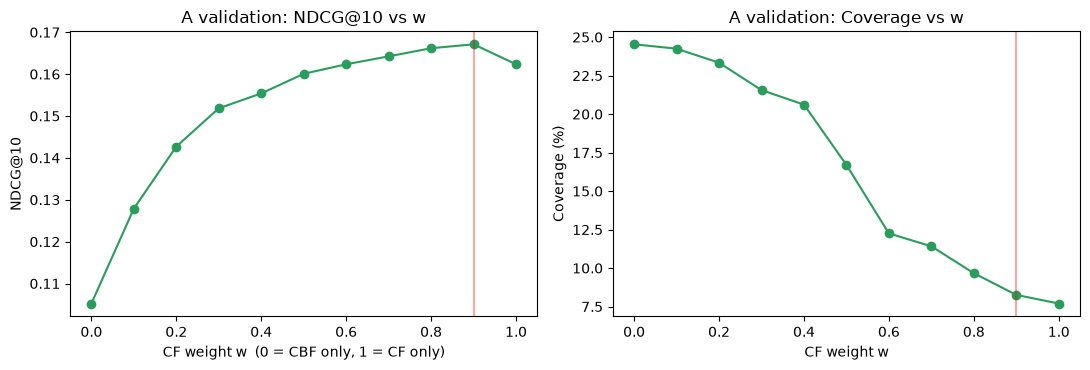

In [32]:
# 4-1. A 공통 후보 · 가중치 탐색 (A-validation)
A_HIST = pd.concat([a['train'], a['validation']], ignore_index=True)      # test 평가의 관측 이력
A_USERS = sorted(A_HIST.user_id.unique())
COMMON_A = sorted(set(A_CAND) & set(A_HIST.artist_id))
print(f'A 공통 후보 {len(COMMON_A):,}개 (CBF 후보 {len(A_CAND):,}개 중 관측된 아티스트) | 평가 사용자 {len(A_USERS):,}명')

t0 = time.time()
A_TRAIN_USERS = sorted(a['train'].user_id.unique())
v_cf, _ = recommend_ucf(a['train'], k=CF_CFG['k'], value=CF_CFG['weight'], topk=POOL, allowed=set(COMMON_A))
v_cbf, _ = recommend(a['train'], V, CBF_CFG['weight_mode'], COMMON_A, topk=POOL)
val_rows = []
for w in W_GRID:
    s, _ = evaluate(fuse(v_cf, v_cbf, w), a['validation'], A_TRAIN_USERS, COMMON_A)
    val_rows.append({'w_cf': w, **{m: s[m] for m in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}})
val_w = pd.DataFrame(val_rows)
# 선택 기준: NDCG@10 최대 (동률은 Recall@10 → Precision@10 → 작은 w), CF·CBF 노트북과 같은 규칙
val_w = val_w.sort_values(['ndcg10', 'recall10', 'precision10', 'w_cf'], ascending=[False, False, False, True]).reset_index(drop=True)
BEST_W = float(val_w.iloc[0].w_cf)
print(f'가중치 탐색 {time.time()-t0:.1f}초')
display(val_w.round(4))
print(f'A-validation NDCG@10 기준으로 확정한 CF 가중치 w = {BEST_W}  (CBF 가중치 = {1 - BEST_W:.1f})')
val_w.sort_values('w_cf').to_csv(OUT / 'A_validation_hybrid_weight.csv', index=False)

vw = val_w.sort_values('w_cf')
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(vw.w_cf, vw.ndcg10, marker='o', color='#2a9d5c'); axs[0].axvline(BEST_W, color='red', alpha=.35)
axs[0].set(xlabel='CF weight w  (0 = CBF only, 1 = CF only)', ylabel='NDCG@10', title='A validation: NDCG@10 vs w')
axs[1].plot(vw.w_cf, vw.catalog_coverage * 100, marker='o', color='#2a9d5c'); axs[1].axvline(BEST_W, color='red', alpha=.35)
axs[1].set(xlabel='CF weight w', ylabel='Coverage (%)', title='A validation: Coverage vs w')
plt.tight_layout(); plt.savefig(OUT / 'fig_A_hybrid_weight.png', dpi=160); plt.show()

### Test 추천 생성
확정한 $w$로 Test 추천을 만듭니다. 이때 관측 이력은 train + validation입니다(validation 정답까지 이력으로 활용). Test 기록은 유사도·프로필·인기도 계산에 전혀 쓰지 않습니다. 네 모델 모두 같은 후보(`COMMON_A`)에서만 추천하고, 생성 직후 `check_recs()`로 검증합니다.

In [33]:
# 4-2. A Test 추천 생성 (관측 이력 = train + validation)
t0 = time.time()
a_cf50, _ = recommend_ucf(A_HIST, k=CF_CFG['k'], value=CF_CFG['weight'], topk=POOL, allowed=set(COMMON_A))
a_cbf50, _ = recommend(A_HIST, V, CBF_CFG['weight_mode'], COMMON_A, topk=POOL)
a_pop, _ = recommend_pop(A_HIST, allowed=set(COMMON_A))
A_RECS = {'pop': a_pop, 'cf': top(a_cf50), 'cbf': top(a_cbf50), 'hybrid': fuse(a_cf50, a_cbf50, BEST_W)}
print(f'A Test 추천 생성 {time.time()-t0:.1f}초')
for m, r in A_RECS.items():
    check_recs(f'A {m}', A_HIST, r, COMMON_A)
    r.to_csv(OUT / f'A_test_recs_common_{m}.csv', index=False)
pd.DataFrame({'artist_id': COMMON_A}).to_csv(OUT / 'A_common_candidates.csv', index=False)

# 간이 확인 (본격 비교·통계는 04 노트북)
quick = []
for m, r in A_RECS.items():
    s, _ = evaluate(r, a['test'], A_USERS, COMMON_A); quick.append({'model': m, **{x: s[x] for x in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}})
print('\n[A Test · 공통 후보 기준 간이 확인]'); display(pd.DataFrame(quick).set_index('model').round(4))

A Test 추천 생성 1.7초
  A pop: 검증 통과 (추천 18,770행, 사용자 1,877명)
  A cf: 검증 통과 (추천 18,770행, 사용자 1,877명)
  A cbf: 검증 통과 (추천 18,770행, 사용자 1,877명)
  A hybrid: 검증 통과 (추천 18,770행, 사용자 1,877명)

[A Test · 공통 후보 기준 간이 확인]


,precision10,recall10,ndcg10,catalog_coverage
model,,,,
pop,0.0669,0.0685,0.0783,0.0028
cf,0.1663,0.1692,0.2039,0.0763
cbf,0.0946,0.0965,0.1106,0.2445
hybrid,0.1701,0.1733,0.2095,0.0840


## 5. Dataset B: 외부 평가
Dataset B의 평가는 두 단계로 나눕니다. CF 노트북의 평가 조건이 기준이므로 5-1을 먼저 수행합니다.

**5-1. 공식 결과 (CF 노트북 조건, 기준 수치).** CF·인기순을 CF 노트북과 똑같은 조건으로 추천하고 평가합니다.
- 관측 이력: B 전체 `train + validation`, 정답: B 전체 `test`, 평가 사용자: 이력이 있는 모든 사용자
- 추천 후보: B 이력에 등장한 모든 아티스트 (제한 없음)
- CF 노트북이 저장한 `cf_outputs/evaluation_summary.csv`가 있으면 재계산 값과 대조하여 같은 수치인지 확인합니다.

**5-2. 공통 후보 기준 (보조 기준).** CBF와 하이브리드는 태그 정보가 있는 아티스트(A 번호)에서만 추천할 수 있습니다. 그런데 B 전체 파일은 아티스트 번호가 mbid 문자열이라 태그와 정확히 연결되지 않으므로, 이 두 모델은 B 전체 조건으로 평가할 수 없습니다. 네 모델을 같은 조건에서 비교하기 위해 다음 기준을 따로 둡니다. 이 기준의 CF 수치는 5-1의 공식 수치와 다르며, 상대 비교에만 사용합니다.
- **후보:** `content_candidate_artists.csv`의 공통 후보 ∩ B 관측 이력에 등장한 아티스트
- **정답·평가 사용자:** `content_external_candidates/test.csv` (공통 후보로 제한된 정답)
- **관측 이력:** 네 모델 모두 `content_external_candidates`(train+validation). B 전체 파일과는 행이 대응되지 않아(외부 후보 파일의 (사용자, 재생수) 중 B 전체 파일에 있는 것은 약 56%) 섞어 쓰지 않습니다.
- **CBF:** A에서 만든 TF-IDF를 재학습 없이 사용 (CBF 노트북과 동일)
- **가중치 w:** A-validation에서 확정한 값 그대로. B 결과로 바꾸지 않습니다.

In [34]:
# 5-1. B 공식 결과: CF 노트북과 동일한 조건의 CF·인기순
B_OFFICIAL = {}
if RUN_B_FULL:
    b_hist_off = pd.concat([b_full['train'], b_full['validation']], ignore_index=True)
    B_OFF_USERS = sorted(b_hist_off.user_id.unique())
    t0 = time.time()
    off_cf, OFF_CF_CAND = recommend_ucf(b_hist_off, k=CF_CFG['k'], value=CF_CFG['weight'])
    off_pop, OFF_POP_CAND = recommend_pop(b_hist_off)
    OFF_CF_SUM, _ = evaluate(off_cf, b_full['test'], B_OFF_USERS, OFF_CF_CAND)
    OFF_POP_SUM, _ = evaluate(off_pop, b_full['test'], B_OFF_USERS, OFF_POP_CAND)
    print(f'B 공식 조건 추천·평가 {time.time()-t0:.1f}초')
    for name, r, c in [('B official CF', off_cf, OFF_CF_CAND), ('B official Popularity', off_pop, OFF_POP_CAND)]:
        check_recs(name, b_hist_off, r, c)
    off_cf.to_csv(OUT / 'B_test_recs_official_cf.csv', index=False)
    off_pop.to_csv(OUT / 'B_test_recs_official_pop.csv', index=False)
    B_OFFICIAL = pd.DataFrame([{'model': 'CF', **OFF_CF_SUM}, {'model': 'Popularity', **OFF_POP_SUM}])
    B_OFFICIAL.to_csv(OUT / 'B_official_summary.csv', index=False)
    print('\n[B Test · 공식 조건(CF 노트북 기준)]'); display(B_OFFICIAL.set_index('model')[['precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'users']].round(4))
    # CF 노트북이 저장한 공식 결과와 대조 (있을 때)
    cf_ref = CF_CONFIG_PATH.parent / 'evaluation_summary.csv'
    if cf_ref.exists():
        ref = pd.read_csv(cf_ref); ref = ref[ref.dataset == 'B_test']
        for m, S in [('CF', OFF_CF_SUM), ('Popularity', OFF_POP_SUM)]:
            r_ = ref[ref.model.str.contains(m)]
            if len(r_):
                d = abs(S['ndcg10'] - float(r_.iloc[0].ndcg10))
                print(f"  {m}: CF 노트북 공식 NDCG@10 {float(r_.iloc[0].ndcg10):.6f} vs 재계산 {S['ndcg10']:.6f} → {'일치' if d < 1e-6 else '불일치 — 확인 필요'}")
else:
    print('B 전체 파일(Lastfm.360k-b/train·validation·test.csv)이 없어 B 공식 조건 평가를 건너뜁니다.')

B 공식 조건 추천·평가 4.5초
  B official CF: 검증 통과 (추천 99,970행, 사용자 9,997명)
  B official Popularity: 검증 통과 (추천 99,970행, 사용자 9,997명)

[B Test · 공식 조건(CF 노트북 기준)]


,precision10,recall10,ndcg10,catalog_coverage,catalog_size,users
model,,,,,,
CF,0.1165,0.1249,0.1462,0.0645,48981,9997
Popularity,0.0322,0.0342,0.0394,0.0005,48981,9997


  CF: CF 노트북 공식 NDCG@10 0.146210 vs 재계산 0.146210 → 일치
  Popularity: CF 노트북 공식 NDCG@10 0.039385 vs 재계산 0.039385 → 일치


In [35]:
# 5-2. B 공통 후보 기준 추천 생성 (보조 기준)
B_RECS = {}
if RUN_B:
    # 진단 결과: B 전체 파일(artist_id가 'mbid:...' 문자열)과 외부 후보 파일(A 정수 번호)은 서로 행이 대응되지 않습니다
    #  (외부 후보 파일의 (사용자, 재생수) 중 B 전체 파일에 있는 것은 약 56%뿐 - 여러 B 번호가 하나의 A 아티스트로 합쳐진 것으로 보임).
    # 따라서 B 전체 파일을 A 번호로 변환할 수 없습니다. 네 모델을 같은 조건으로 비교하기 위해 이 보조 기준에서는 모든 모델이
    # 외부 후보 파일(A 번호, train+validation)만을 관측 이력으로 사용합니다. (CF의 기준 수치는 5-1의 공식 결과이며, 이 결과는 상대 비교용입니다.)
    b_hist_ext = pd.concat([b_ext['train'], b_ext['validation']], ignore_index=True)
    b_hist_full = b_hist_ext          # CF·인기순도 같은 이력 사용
    B_CAND = sorted(b_map.loc[b_map.recommendation_candidate.eq(1), 'a_artist_id'].tolist())
    assert set(B_CAND) <= set(A_CAND), 'B 공통 후보가 A의 CBF 후보에 포함되지 않음'
    COMMON_B = sorted(set(B_CAND) & set(b_hist_ext.artist_id))
    B_USERS = sorted(set(b_ext['test'].user_id) & set(b_hist_ext.user_id) & set(b_hist_full.user_id))
    b_truth = b_ext['test'][b_ext['test'].user_id.isin(B_USERS)]
    print(f'B 공통 후보 {len(COMMON_B):,}개 (매핑 후보 {len(B_CAND):,}개) | 평가 사용자 {len(B_USERS):,}명')

    t0 = time.time()
    b_cf50, _ = recommend_ucf(b_hist_full, k=CF_CFG['k'], value=CF_CFG['weight'], topk=POOL, allowed=set(COMMON_B))
    b_cbf50, _ = recommend(b_hist_ext, V, CBF_CFG['weight_mode'], COMMON_B, topk=POOL)
    b_pop, _ = recommend_pop(b_hist_full, allowed=set(COMMON_B))
    B_RECS = {'pop': b_pop, 'cf': top(b_cf50), 'cbf': top(b_cbf50), 'hybrid': fuse(b_cf50, b_cbf50, BEST_W)}
    print(f'B 추천 생성 {time.time()-t0:.1f}초')
    both_hist = pd.concat([b_hist_full, b_hist_ext], ignore_index=True)
    for m, r in B_RECS.items():
        r = r[r.user_id.isin(B_USERS)].reset_index(drop=True); B_RECS[m] = r
        check_recs(f'B {m}', both_hist, r, COMMON_B)
        r.to_csv(OUT / f'B_test_recs_common_{m}.csv', index=False)
    pd.DataFrame({'artist_id': COMMON_B}).to_csv(OUT / 'B_common_candidates.csv', index=False)
    pd.DataFrame({'user_id': B_USERS}).to_csv(OUT / 'B_eval_users.csv', index=False)

    quick = []
    for m, r in B_RECS.items():
        s, _ = evaluate(r, b_truth, B_USERS, COMMON_B); quick.append({'model': m, **{x: s[x] for x in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}})
    print('\n[B Test · 공통 후보·공통 정답 기준 간이 확인]'); display(pd.DataFrame(quick).set_index('model').round(4))
else:
    print('B 파일이 없어 B 부분을 건너뜁니다.')

B 공통 후보 8,161개 (매핑 후보 9,282개) | 평가 사용자 9,931명
B 추천 생성 5.9초
  B pop: 검증 통과 (추천 99,310행, 사용자 9,931명)
  B cf: 검증 통과 (추천 99,310행, 사용자 9,931명)
  B cbf: 검증 통과 (추천 99,310행, 사용자 9,931명)
  B hybrid: 검증 통과 (추천 99,310행, 사용자 9,931명)

[B Test · 공통 후보·공통 정답 기준 간이 확인]


,precision10,recall10,ndcg10,catalog_coverage
model,,,,
pop,0.0313,0.0448,0.0456,0.0027
cf,0.1082,0.1676,0.1690,0.3034
cbf,0.0564,0.0894,0.0847,0.4374
hybrid,0.1111,0.1727,0.1718,0.3165


## 6. 설정 저장 · 산출물 정리

In [36]:
# 6-1. 저장
(OUT / 'config.json').write_text(json.dumps({
    'cf': CF_CFG, 'cbf': CBF_CFG,
    'hybrid': {'method': 'weighted RRF', 'rrf_c': RRF_C, 'pool': POOL, 'w_cf': BEST_W, 'w_grid': W_GRID,
               'selection': 'Dataset A validation NDCG@10 (tie: recall10, precision10, smaller w)'},
    'common_candidates': {'A': len(COMMON_A), 'B': len(COMMON_B) if RUN_B else None},
    'ran_B': RUN_B, 'ran_B_official': bool(RUN_B_FULL), 'b_official': {'basis': 'CF notebook conditions (B full history, all candidates, full truth)', 'catalog_cf': int(len(OFF_CF_CAND)) if RUN_B_FULL else None, 'users': len(B_OFF_USERS) if RUN_B_FULL else None},
    'seed': SEED, 'topk': TOPK}, indent=2, ensure_ascii=False), encoding='utf-8')
print('산출물 위치:', OUT)
print('산출물:', sorted(p.name for p in OUT.iterdir()))
print('다음 단계: 04_Integration_Evaluation 노트북을 실행하세요.')

산출물 위치: ./hybrid_outputs
산출물: ['A_common_candidates.csv', 'A_test_recs_common_cbf.csv', 'A_test_recs_common_cf.csv', 'A_test_recs_common_hybrid.csv', 'A_test_recs_common_pop.csv', 'A_validation_hybrid_weight.csv', 'B_artist_id_map.csv', 'B_common_candidates.csv', 'B_eval_users.csv', 'B_official_summary.csv', 'B_test_recs_common_cbf.csv', 'B_test_recs_common_cf.csv', 'B_test_recs_common_hybrid.csv', 'B_test_recs_common_pop.csv', 'B_test_recs_official_cf.csv', 'B_test_recs_official_pop.csv', 'config.json', 'fig_A_hybrid_weight.png']
다음 단계: 04_Integration_Evaluation 노트북을 실행하세요.


## 수업에서 다루지 않은 함수·라이브러리 설명
CF·CBF 노트북의 함수 설명표(`csr_matrix`, `normalize`, `argpartition`, `put_along_axis`, `fill_diagonal`, `TfidfTransformer` 등)는 각 노트북의 해당 절과 같습니다. 이 노트북에서 추가로 쓴 것은 아래와 같습니다.

| 함수/기법 | 역할 | 이 노트북에서 쓴 방식 |
|---|---|---|
| Reciprocal Rank Fusion | 서로 다른 순위 목록을 점수 척도 없이 결합 | `fuse()`: `w/(60+rank_CF) + (1−w)/(60+rank_CBF)`. Cormack et al. (2009) |
| `df.groupby([...], as_index=False).s.sum()` | 같은 (사용자, 아티스트)의 점수를 합산 | CF·CBF 양쪽에 등장한 아티스트의 RRF 점수 합산 |
| `df.groupby('user_id').cumcount()` | 그룹 안에서 0부터 순번 매김 | 정렬 후 사용자별 순위(rank) 부여 |
| `df.assign(s=...)` | 새 열을 추가한 복사본 반환 | 원본 추천 목록을 바꾸지 않고 RRF 점수 열 추가 |
| `pd.concat(..., ignore_index=True)` | 표를 위아래로 이어 붙임 | train+validation 관측 이력, CF·CBF 목록 결합 |
| `zipfile.ZipFile(...).open(name)` | ZIP 안의 파일을 압축 해제 없이 읽음 | 전처리 ZIP 로드 |